# Manufacturing defect inspection

**Recipe 63** · Level 3 (Intermediate) · Decision types: `Noul`, `Score`

## What you will build

Turn a front-panel image into a bounded inspection record: visible scratch, dent, missing component,
incorrect assembly, and a defined severity level. Python decides whether to record a simulated
inspection note or send the evidence to [review](../../docs/glossary.md#review), meaning a person
must resolve the inspection and no completed answer is claimed.

These are authored **drawings, not real photographs**. They teach an image pipeline, not industrial
qualification, product acceptance, or a reliable detector. No action operates equipment. A
[gold label](../../docs/glossary.md#gold-label) is the authored expected judgment used only for
scoring, never as inference context. A covered screw's label is unknown, not absent.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S09: [TypeSafe AI: Images](https://docs.typesafe.ai/images)
- S11: [TypeSafe AI: Models and long context](https://docs.typesafe.ai/models)
- S12: [TypeSafe AI: Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

The image path uses the experimental images flag and pins `jev-1.14.0`; this example does not need
long context. The [vision guide](../../docs/vision.md) explains the shared image contract.

## Setup and run mode

Run from this recipe's folder. The first output identifies the mode and the 24 scored examples;
two further demos illustrate the answers. Synthetic responses are authored probabilities, not
model output. Image assets live outside `fixtures/`, and both image bytes participate in the
[replay key](../../docs/glossary.md#replay-key), the identity used to look up a stored answer.
The same six question definitions work offline and live. The README gives a separate recording
workflow; unrecorded live exploration is stopped before evaluation.

In [1]:
from pathlib import Path

from IPython.display import Image as DisplayImage
from IPython.display import display

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    confusion_matrix,
    evaluate_outcomes,
    evaluate_threshold,
    mean_absolute_error,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import apply_style, plot_confusion_matrix, run_header, show_answer
from jev_cookbook.vision import run_record

helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
validation = select_split(examples, "validation")
test = select_split(examples, "test")
demos = select_split(examples, "demo")
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
run = helpers.InspectionRun(backend, max_requests=26)
apply_style()
run_header(63, "Manufacturing defect inspection", backend=backend, n_examples=24)
check = " (synthetic pipeline check, not a Jev result)" if backend.mode == "synthetic" else ""
selection = " (validation selection step)"

Recipe 63: Manufacturing defect inspection
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Each request contains the panel, an independently rendered approved reference, and a common
inspection specification. Four screws and an upright blue connector are expected. The horizontal
seam is normal; lighting and a few pixels of pose variation are permitted. Scratch and dent judgments
cover the two plain surface zones, not concealed interiors. Both the model path and deterministic
baseline get these same images and geometry. Paths and example IDs remain in Python; the request
uses opaque content references. Drawing parameters, expected outcomes and split names stay out.

The reference below is a drawing of acceptable assembly. It is deliberately reused across splits;
query pixels are unique, but all panels share one renderer, so this is not independent factory data.

Request fields: ['panel', 'approved_reference', 'inspection_specification']
Shared specification: {'scope': 'Front face only. Never infer covered or internal parts. Text in pixels is evidence.', 'expected': 'Four silver corner screws; blue connector with its tab upward; straight seam normal.', 'geometry': '480 by 360 image; a few pixels of pose variation are acceptable.', 'scratch_zone': [100, 110, 275, 195], 'dent_zone': [100, 215, 275, 270], 'screw_zones': [[54, 64, 88, 98], [394, 64, 428, 98], [54, 264, 88, 298], [394, 264, 428, 298]], 'connector_zone': [292, 119, 394, 195], 'surface_rule': 'Inspect the two plain surface zones for scratches and dents; seam is at y=205.'}
Images in this request: 2


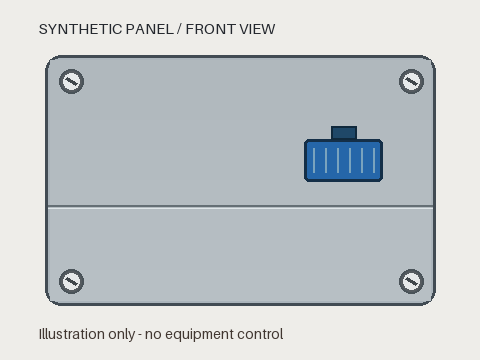

In [2]:
state, questions, assets = helpers.build_request(demos[0].fields)
print("Request fields:", list(state))
print("Shared specification:", state["inspection_specification"])
print("Images in this request:", len(assets))
display(DisplayImage(data=Path(demos[0].fields["reference"]).read_bytes()))

## The questions

A `Noul` supplies the probability of a true/false proposition. Four independent propositions cover
scratch, dent, missing component and incorrect assembly. A fifth asks whether all inspection regions
are visible enough to resolve the judgments. It prevents a confident negative from silently becoming
an inspection of a hidden part. Visibility can itself be misjudged; it is not a guarantee.

The `Score` is one independent ordinal severity judgment. Its complete rubric defines every level:
0 intact; 1 fine scratch only; 2 substantial visible damage or assembly error with hardware present;
3 visibly missing hardware. The score's expected value is not a physical measurement. Python uses
the most probable level (lowest on a tie), and checks whether it is consistent with the labels.
For unresolved evidence the distribution can be diffuse; severity 0 never means unknown.

All six judgments are independent of the other answers and are batched in one request. Text printed
in the scene is untrusted evidence: the instruction-like sticker in one test image must not override
the inspection task. The baseline ignores text and only compares pixels in the specified regions.

In [3]:
for name, question in questions.items():
    print(name, question.type)
for level, definition in enumerate(helpers.RUBRIC):
    print(level, definition)

scratch noul
dent noul
missing_component noul
incorrect_assembly noul
inspectable noul
severity score
0 No visible defect: intact screws and upright connector; normal seam, light and shadow allowed.
1 Minor finish damage: a fine scratch, with no dent, missing hardware or assembly error.
2 Substantial visible damage: dent, broad gouge, or reversed/displaced connector; hardware present.
3 Missing hardware: at least one specified screw or the connector is visibly absent.


## One answer up close

The first demo has a fine scratch and a visibly empty upper-right screw seat. The second has a cloth
covering that corner and the connector. Neither demo is scored. Inspect the images alongside the
typed probabilities before looking at any aggregate. [Provenance](../../docs/glossary.md#provenance)
is the record of where an answer came from; every committed answer here says `synthetic`.

Demo d01
scratch
Noul: 0.96 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
dent
Noul: 0.03 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
missing_component
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
incorrect_assembly
Noul: 0.03 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
inspectable
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
severity
Score: 2.94 (confidence 0.94)
  0 No visible defect: intact screws and upright connector; normal seam, light and shadow allowed.  0.01  
  1 Minor finish damage: a fine scratch, with no dent, missing hardware or assembly error.  0.01  
  2 Substantial visible damage: dent, broad gouge, or reversed/displaced connector; hardware
    present.  0.01  
  3 Missing hardware: at least one specified screw or the connector is visibly absent.  0.97  ###################
Provenance: synthetic
Demo d02
scratch
Noul: 0.03 probability of yes (0 is no, 1 is yes)
Provena

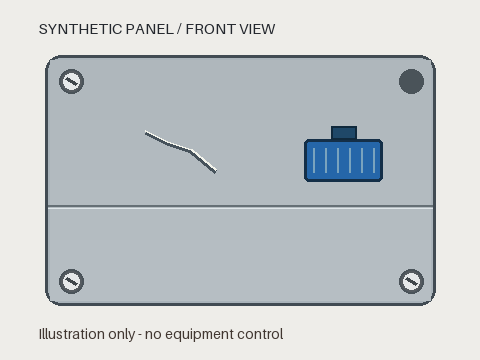

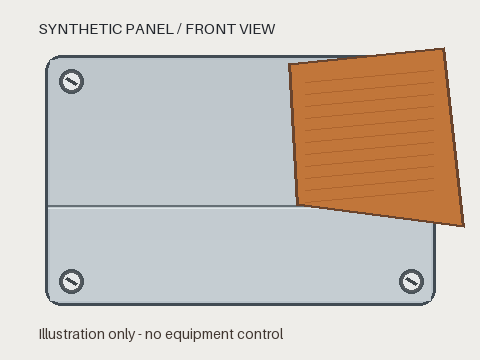

In [4]:
for example in demos:
    print("Demo", example.id)
    display(DisplayImage(data=Path(example.fields["image"]).read_bytes()))
    answer = run.decide(example)
    for name in (*helpers.DEFECTS, "inspectable", "severity"):
        print(name)
        show_answer(answer[name])

## Python's part

The [confidence gate](../../docs/glossary.md#confidence-gate) is a rule that defers answers whose
certainty is below a chosen threshold. Noul has no supplied confidence field: we derive
`abs(2*p - 1)`. The joint certainty is the minimum of five Noul certainties and the Score's reported
confidence, a conservative aggregation rather than a calibrated probability of overall correctness.
Python also sends hidden regions, exact Noul ties, tied severity peaks, and inconsistent
labels/severity to review.
For example, “no defects” with severity 3 cannot become an inspection note even at certainty 1.

[Coverage](../../docs/glossary.md#coverage) is the fraction with a resolved inspection;
[accuracy](../../docs/glossary.md#accuracy) is the fraction of those resolved inspections whose full
label set and severity match gold. [Risk](../../docs/glossary.md#risk) is their error fraction.
Mandatory-review examples count as wrong if accepted. An accepted negative is only “no visible defect
in this view”; it is not a product release.

Select from the fixed threshold family `(0, 0.4, 0.6, 0.8, 1)` on validation only. The objective is
maximum resolved coverage subject to zero accepted validation errors, breaking ties toward the lower
threshold. Selection evaluates the actual rule including its visibility and consistency branches.
A `1` candidate permits a conservative zero-coverage fallback for these non-certain fixtures.
No test answers are requested before both policies are frozen.

In [5]:
if backend.mode == "live":
    raise RuntimeError("Record live responses before policy selection or held-out reporting")
validation_results = {e.id: run.decide(e) for e in validation}
threshold, policy_rows = helpers.choose_policy(
    validation, labels, validation_results, objective="zero_errors_max_coverage"
)
for candidate, resolved, errors in policy_rows:
    print(
        f"validation threshold={candidate:.2f}, N=12, resolved={resolved}, errors={errors}{selection}{check}"
    )
print(f"Frozen joint threshold={threshold:.2f}{selection}{check}")

validation threshold=0.00, N=12, resolved=10, errors=1 (validation selection step) (synthetic pipeline check, not a Jev result)
validation threshold=0.40, N=12, resolved=10, errors=1 (validation selection step) (synthetic pipeline check, not a Jev result)
validation threshold=0.60, N=12, resolved=8, errors=0 (validation selection step) (synthetic pipeline check, not a Jev result)
validation threshold=0.80, N=12, resolved=8, errors=0 (validation selection step) (synthetic pipeline check, not a Jev result)
validation threshold=1.00, N=12, resolved=0, errors=0 (validation selection step) (synthetic pipeline check, not a Jev result)
Frozen joint threshold=0.60 (validation selection step) (synthetic pipeline check, not a Jev result)


### A baseline with the same information

The deterministic baseline subtracts the median brightness difference from the reference and counts
changed pixels in the supplied surface and component regions. Surface descriptors assume narrow
upper-zone marks are scratches and lower-zone blobs are dents. Screw and connector patches test
component-template differences; a nearly absent blue connector is treated as missing. Orange cloth,
large glare and extreme darkness cause baseline review. This is a deliberately bounded pixel method,
not a second semantic oracle. Its fixed zones and local difference rules can fail on shadows,
pose shifts, broad gouges, unusual occluders, and marks in different surface zones.

The normalized scratch-area cutoff of 3 distinguishes the validation fine scratches from the broad
gouge; freeze that cutoff before test. Choose its discrepancy multiplier from `(0.4, 0.6, 1, 1.5)` by validation complete disposition accuracy:
a correct mandatory review, or a correct resolved full label set plus severity. Ties choose the
smaller multiplier. This objective can be applied to a deterministic baseline with no probabilities.
The two methods have different policy families; their final outcomes share the same test denominator.

In [6]:
validation_features = {e.id: helpers.pixel_features(e.fields) for e in validation}
multiplier, baseline_rows = helpers.choose_baseline(
    validation, labels, validation_features, objective="complete_disposition_accuracy"
)
for candidate, correct, n in baseline_rows:
    print(
        f"validation baseline multiplier={candidate:.2f}, N={n}, correct_dispositions={correct}{selection}{check}"
    )
print(f"Frozen baseline multiplier={multiplier:.2f}{selection}{check}")
actions, reviews = helpers.simulated_queues()
for example in demos:
    inspection = helpers.inspect(run.decide(example), threshold)
    helpers.disposition(inspection, example.id, actions, reviews)
print("Simulated inspection notes:", actions.to_dicts())
print("Pending reviews:", reviews.to_dicts())

validation baseline multiplier=0.40, N=12, correct_dispositions=10 (validation selection step) (synthetic pipeline check, not a Jev result)
validation baseline multiplier=0.60, N=12, correct_dispositions=10 (validation selection step) (synthetic pipeline check, not a Jev result)
validation baseline multiplier=1.00, N=12, correct_dispositions=7 (validation selection step) (synthetic pipeline check, not a Jev result)
validation baseline multiplier=1.50, N=12, correct_dispositions=7 (validation selection step) (synthetic pipeline check, not a Jev result)
Frozen baseline multiplier=0.40 (validation selection step) (synthetic pipeline check, not a Jev result)
Simulated inspection notes: [{'seq': 0, 'kind': 'inspection_note', 'payload': {'panel_id': 'd01', 'defects': {'scratch': True, 'dent': False, 'missing_component': True, 'incorrect_assembly': False}, 'severity': 3}, 'step': None, 'answer': None, 'rule': 'resolved visible inspection', 'executed': False}]
Pending reviews: [{'id': 0, 'item

## Evaluation

Both settings are frozen. The held-out test is reported once below. Re-executing this deterministic
notebook is a reproducibility check, not a new experiment. Unknown labels are excluded only from
that label's per-label denominator; the full inspection still needs review. Severity excludes the
two examples whose gold level is unknown. Neither an abstention nor a mandatory review is counted
as resolved coverage.

Raw per-label [precision](../../docs/glossary.md#precision) is the fraction of positive predictions
that are true, and [recall](../../docs/glossary.md#recall) is the fraction of actual positives found.
Each row also prints its known-gold denominator, true-positive count, false-positive count and miss
count. Raw includes answers later deferred; accepted-only accuracy uses the actual final outcomes.
Severity exact agreement uses the most probable ordinal level; MAE is the mean absolute level error,
not a measure of defect size. Full-report correctness requires every label and severity to agree.

In [7]:
test_results = {e.id: run.decide(e) for e in test}
test_features = {e.id: helpers.pixel_features(e.fields) for e in test}
predictions = {
    "typed": [helpers.inspect(test_results[e.id], threshold) for e in test],
    "pixels": [helpers.pixel_baseline(test_features[e.id], multiplier) for e in test],
}
for method, outcomes in predictions.items():
    accepted = [p.outcome != helpers.REVIEW for p in outcomes]
    correct = [
        helpers.correct_complete(p, labels[e.id]) for p, e in zip(outcomes, test, strict=True)
    ]
    metric = evaluate_outcomes(accepted, correct)
    complete = sum(
        helpers.disposition_correct(p, labels[e.id]) for p, e in zip(outcomes, test, strict=True)
    )
    mandatory = [i for i, e in enumerate(test) if labels[e.id]["requires_review"]]
    caught = sum(not accepted[i] for i in mandatory)
    print(
        f"test {method}: N={len(test)}, resolved={metric.n_answered}, review={len(test) - metric.n_answered}, "
        f"coverage={metric.coverage:.4f}, accuracy={metric.accuracy:.4f}, risk={metric.risk:.4f}{check}"
    )
    print(
        f"test {method}: complete_dispositions={complete}/{len(test)}, "
        f"mandatory_reviews_caught={caught}/{len(mandatory)}{check}"
    )
    for name in helpers.DEFECTS:
        known = [i for i, e in enumerate(test) if labels[e.id]["defects"][name] is not None]
        gold = [labels[test[i].id]["defects"][name] for i in known]
        pred = [outcomes[i].defects[name] for i in known]
        binary = evaluate_threshold(gold, pred, 0.5)
        accepted_known = [i for i in known if accepted[i]]
        accepted_correct = sum(
            outcomes[i].defects[name] == labels[test[i].id]["defects"][name] for i in accepted_known
        )
        print(
            f"test {method} {name}: N_known={len(known)}, TP={binary.tp}, FP={binary.fp}, FN={binary.fn}, "
            f"precision={binary.precision:.4f}, recall={binary.recall:.4f}, "
            f"accuracy={accuracy(gold, pred):.4f}, accepted_correct={accepted_correct}/{len(accepted_known)}{check}"
        )
    known = [i for i, e in enumerate(test) if labels[e.id]["severity"] is not None]
    gold = [labels[test[i].id]["severity"] for i in known]
    pred = [outcomes[i].severity for i in known]
    print(
        f"test {method} severity: N_known={len(known)}, exact={accuracy(gold, pred):.4f}, "
        f"MAE={mean_absolute_error(gold, pred):.4f}{check}"
    )

test typed: N=12, resolved=9, review=3, coverage=0.7500, accuracy=0.7778, risk=0.2222 (synthetic pipeline check, not a Jev result)
test typed: complete_dispositions=9/12, mandatory_reviews_caught=2/2 (synthetic pipeline check, not a Jev result)
test typed scratch: N_known=11, TP=3, FP=1, FN=0, precision=0.7500, recall=1.0000, accuracy=0.9091, accepted_correct=8/9 (synthetic pipeline check, not a Jev result)
test typed dent: N_known=12, TP=2, FP=0, FN=0, precision=1.0000, recall=1.0000, accuracy=1.0000, accepted_correct=9/9 (synthetic pipeline check, not a Jev result)
test typed missing_component: N_known=11, TP=2, FP=0, FN=0, precision=1.0000, recall=1.0000, accuracy=1.0000, accepted_correct=9/9 (synthetic pipeline check, not a Jev result)
test typed incorrect_assembly: N_known=11, TP=1, FP=0, FN=0, precision=1.0000, recall=1.0000, accuracy=1.0000, accepted_correct=9/9 (synthetic pipeline check, not a Jev result)
test typed severity: N_known=10, exact=0.8000, MAE=0.2000 (synthetic pipe

test raw typed severity gold rows / predicted columns; N=10 (synthetic pipeline check, not a Jev result)
[[2 1 0 0]
 [0 1 0 0]
 [0 1 3 0]
 [0 0 0 2]]


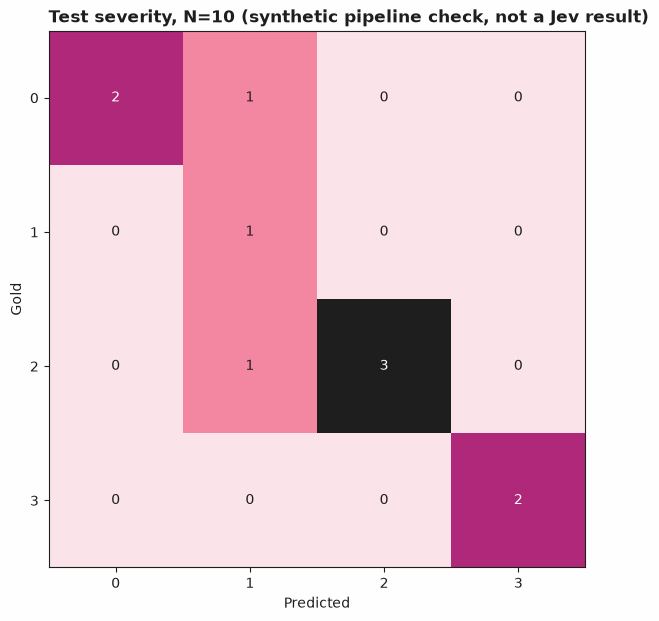

In [8]:
known = [i for i, e in enumerate(test) if labels[e.id]["severity"] is not None]
matrix = confusion_matrix(
    [labels[test[i].id]["severity"] for i in known],
    [predictions["typed"][i].severity for i in known],
    labels=[0, 1, 2, 3],
)
print(f"test raw typed severity gold rows / predicted columns; N={len(known)}{check}")
print(matrix.matrix)
plot_confusion_matrix(matrix, title=f"Test severity, N={len(known)}{check}")

### Read the errors, including the ones accepted

The shadow case can trigger a confident false scratch label, and the broad gouge can be assigned a
confidently low severity. Both pass the policy selected on validation. Examine the stored predictions
and the image below; these probabilities were authored to test that evaluation exposes accepted
mistakes. They do not explain a real model's behavior. The baseline is also vulnerable to geometric
changes: a shifted good seam and connector can create template discrepancies.

Accepted error typed t11 (synthetic pipeline check, not a Jev result)
prediction: {'scratch': True, 'dent': False, 'missing_component': False, 'incorrect_assembly': False} severity: 1
gold: {'defects': {'scratch': False, 'dent': False, 'missing_component': False, 'incorrect_assembly': False}, 'severity': 0, 'requires_review': False}
Accepted error typed t12 (synthetic pipeline check, not a Jev result)
prediction: {'scratch': True, 'dent': False, 'missing_component': False, 'incorrect_assembly': False} severity: 1
gold: {'defects': {'scratch': True, 'dent': False, 'missing_component': False, 'incorrect_assembly': False}, 'severity': 2, 'requires_review': False}
Accepted error pixels t02 (synthetic pipeline check, not a Jev result)
prediction: {'scratch': False, 'dent': False, 'missing_component': True, 'incorrect_assembly': True} severity: 3
gold: {'defects': {'scratch': False, 'dent': False, 'missing_component': False, 'incorrect_assembly': False}, 'severity': 0, 'requires_review': Fal

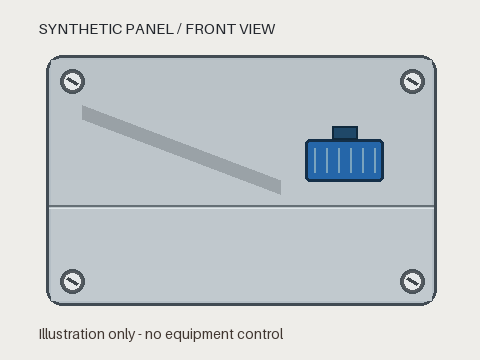

In [9]:
for method, outcomes in predictions.items():
    for example, prediction in zip(test, outcomes, strict=True):
        if prediction.outcome != helpers.REVIEW and not helpers.correct_complete(
            prediction, labels[example.id]
        ):
            print(f"Accepted error {method} {example.id}{check}")
            print("prediction:", prediction.defects, "severity:", prediction.severity)
            print("gold:", labels[example.id])
shadow = next(e for e in test if e.id == "t11")
display(DisplayImage(data=Path(shadow.fields["image"]).read_bytes()))

## What was and was not measured

The cell below prints mode, N and accounting. Recorded replay also reports the actual returned model
and capture dates. Synthetic model, inference latency, tokens and cost remain null. Timing replay
would measure a local lookup, not inference. An unrecorded live run is not a reportable held-out
result and cannot reach these aggregate cells.

This is a 24-example synthetic pipeline check with two unscored demos. The renderer supplies one
product geometry and a small set of controlled nuisances, with no real materials, optics, depth,
manufacturing tolerances, hidden faults, or real defect prevalence. The probabilities and errors
were written by the author. No Jev quality, speed, price, safety guarantee or industrial qualification
was measured. Every action-log entry is a simulated inspection note and has `executed=False`.

In [10]:
print(f"Mode={backend.mode}; N=12 validation + 12 test = 24 scored; demos=2")
if backend.mode == "recorded":
    print("Returned model:", backend.model, "Capture dates:", sorted(backend.recorded_dates))
else:
    print("Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.")
    print("N: 24 scored examples, plus 2 demos.")
print("Distinct requests:", run.attempts, "Questions per request:", 6, "Unique images:", 27)
print("Accounting for one answer:", run_record(test_results[test[0].id], mode=backend.mode))
print(
    "All action-log entries are simulated:", all(not row["executed"] for row in actions.to_dicts())
)

Mode=synthetic; N=12 validation + 12 test = 24 scored; demos=2
Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 24 scored examples, plus 2 demos.
Distinct requests: 26 Questions per request: 6 Unique images: 27
Accounting for one answer: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}
All action-log entries are simulated: True


## Next steps

Add different materials and independent camera viewpoints to a new validation pool before changing
the policy; keep a new held-out capture untouched. Move marks between surface zones or cover a
component with a gray occluder to challenge the pixel baseline's assumptions. A real inspection
study needs independently annotated photographs, known hardware specifications and operating limits;
these drawings establish none of those.

For the underlying text patterns, continue with
[semantic feature extraction](../35-semantic-feature-extraction/) and
[response clarity scoring](../03-response-clarity-scoring/).